# ✍️ Практика: Ridge і LASSO · traceback і assert

**Самостійна робота · ⏱ 3 години · 26 завдань (з них 2 бонусні)**

Спершу — розминка з помилками Python і перевірками даних. Потім основна частина: прогнозуємо місячну виручку магазинів мережі за 27 ознаками, бачимо, як звичайна регресія перенавчається, і виправляємо це за допомогою Ridge і LASSO.

| Блок | Тема | Час |
|---|---|---|
| 1 | Читання traceback і типи помилок | 25 хв |
| 2 | `assert` | 20 хв |
| 3 | Дані і звичайна регресія | 20 хв |
| 4 | Масштабування | 15 хв |
| 5 | Ridge-регресія | 30 хв |
| 6 | LASSO-регресія | 30 хв |
| 7 | Підбір α крос-валідацією | 20 хв |
| 8 | Порівняння, інтерпретація і звіт | 20 хв |

---

### Як працювати з цим блокнотом

1. **Запускайте клітинки по черзі зверху вниз** (Shift + Enter). Спочатку обов'язково запустіть три службові клітинки в розділі «Підготовка».
2. **Пропуски `ВАШ_КОД`** у коді треба замінити на правильний код. Поки пропуск не заповнено, клітинка видасть помилку на кшталт `NameError: name 'ВАШ_КОД' is not defined`, і це нормально. Якщо `'ВАШ_КОД'` стоїть у лапках — впишіть туди текст відповіді (наприклад, `'б'` або `'KeyError'`).
3. **Підказки відкриваються кліком** на «💡 Підказка 1». Спершу спробуйте самі, потім відкрийте першу підказку. Друга підказка майже містить відповідь, тож користуйтеся нею, якщо зовсім застрягли.
4. **Самоперевірка:** після більшості завдань є клітинка з `check(...)`. Запустіть її, і вона напише ✅ або ❌.
5. **Текстові відповіді:** клітинки «✍️ Ваша відповідь» двічі клацніть і напишіть відповідь своїми словами.
6. Завдання з ⭐ — **бонусні**. Якщо часу мало, їх можна пропустити.
7. Застрягли на завданні більше ніж на 10 хвилин — переходьте до наступного і поверніться пізніше.

> 💡 Відкрити в Google Colab: *File → Upload notebook*. Усі дані генеруються всередині блокнота.

---
## Підготовка

Запустіть три клітинки нижче: бібліотеки, дані та функції самоперевірки.

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.float_format', '{:.2f}'.format)

### Дані

**`stores`** — 90 магазинів мережі, ціль — `revenue` (місячна виручка, тис. грн):

| Група | Ознаки |
|---|---|
| Корисні | `area_m2` (площа), `staff` (персонал), `ad_budget` (реклама, тис. грн), `foot_traffic` (відвідувачів на день), `parking_spots` (місць на парковці) |
| «Майже дублікати» | `sales_area_m2` (торгова площа ≈ 80% загальної), `foot_traffic_weekday` (трафік у будні) |
| Непотрібні | `manager_age`, `wifi_speed_mbps`, `plants_count`, `music_volume`, `logo_size_cm`, `noise_01` … `noise_15` |

Список корисних ознак (включно з дублікатами) збережено в змінній `USEFUL`.

**`stores_raw`** — та сама таблиця, але з «брудом»: пропусками і від'ємною виручкою (для блоку 2).

In [79]:
rng = np.random.default_rng(7)
n = 90

# --- Корисні ознаки ---
area = np.round(rng.uniform(80, 400, n))
staff = np.round(np.clip(area / 40 + rng.normal(0, 1.5, n), 2, None)).astype(int)
ad = np.round(rng.uniform(5, 60, n), 1)
traffic = np.round(rng.uniform(200, 2000, n))
parking = rng.integers(0, 40, n)
# --- «Майже дублікати» ---
sales_area = np.round(0.8 * area + rng.normal(0, 8, n))
traffic_weekday = np.round(0.7 * traffic + rng.normal(0, 60, n))

revenue = 50 + 0.9 * area + 12 * staff + 3.5 * ad + 0.15 * traffic + 1.2 * parking + rng.normal(0, 45, n)

data = {
    'area_m2': area, 'sales_area_m2': sales_area, 'staff': staff, 'ad_budget': ad,
    'foot_traffic': traffic, 'foot_traffic_weekday': traffic_weekday, 'parking_spots': parking,
    # --- Непотрібні ознаки з «людськими» назвами ---
    'manager_age': rng.integers(22, 60, n), 'wifi_speed_mbps': rng.integers(20, 500, n),
    'plants_count': rng.integers(0, 25, n), 'music_volume': rng.integers(1, 11, n),
    'logo_size_cm': rng.integers(30, 200, n),
}
for i in range(1, 16):
    data[f'noise_{i:02d}'] = np.round(rng.normal(0, 1, n), 2)

stores = pd.DataFrame(data)
stores['revenue'] = np.round(revenue, 1)

# --- «Сира» копія з проблемами (для блоку 2) ---
stores_raw = stores.copy()
stores_raw.loc[[4, 17, 52], 'ad_budget'] = np.nan
stores_raw.loc[[30, 61], 'revenue'] = [-120.0, -15.5]

USEFUL = ['area_m2', 'sales_area_m2', 'staff', 'ad_budget', 'foot_traffic', 'foot_traffic_weekday', 'parking_spots']
print('stores:', stores.shape, '| stores_raw:', stores_raw.shape)

stores: (90, 28) | stores_raw: (90, 28)


In [80]:
# ⚙️ Службова клітинка: функції для самоперевірки. Просто запустіть її, змінювати нічого не потрібно.
ANSWERS = {
    '1.1': ['KeyError', 'monthly_total', 'б'],
    '1.2': [515.0],
    '1.3': [1.326056],
    '1.4': ['а', 'б', 'в', 'г'],
    '2.1': [1.0],
    '2.2': [3.0, 2.0, 85.0],
    '2.3': [27.0, 1.0],
    '3.1': [63.0, 27.0],
    '3.2': [0.963937, 0.857849, 52.882802],
    '3.3': [9.0],
    '4.1': [0.0, 1.0],
    '4.2': ['а', 'б'],
    '5.1': [0.955971, 0.887555, 46.537892],
    '5.2': [[52.589669, 52.452804, 46.537892, 64.006534, 122.238867], 10.0],
    '5.3': [[375.019938, 369.555799, 325.275714, 201.323089, 48.390323]],
    '6.1': [8.0, 38.636693],
    '6.2': [3.0],
    '6.3': [[24.0, 22.0, 18.0, 8.0, 7.0, 5.0]],
    '6.4': ['l', 'r', 'l'],
    '7.1': [7.196857, 48.225124],
    '7.2': [5.201993, 8.0, 38.367601],
    '7.3': ['б'],
    '8.1': [[52.882802, 48.225124, 38.367601], 'lasso'],
    '8.2': ['foot_traffic', 3.240733],
}

_LATIN = {'a': 'а', 'b': 'б', 'v': 'в', 'c': 'в', 'g': 'г'}

def _same(v, e):
    if isinstance(e, str):
        v = str(v).strip()
        if len(e) == 1:
            v = v.lower()
            return _LATIN.get(v, v) == e.lower() or v == e.lower()
        return v.lower() == e.lower()
    if isinstance(e, list):
        try:
            v = np.asarray(v, dtype=float)
            return v.shape == np.asarray(e).shape and np.allclose(v, e, atol=0.01, rtol=0.005)
        except (TypeError, ValueError):
            return False
    try:
        return abs(float(v) - e) <= max(0.005, abs(e) * 0.005)
    except (TypeError, ValueError):
        return False

def check(task, *values):
    expected = ANSWERS[task]
    if len(values) != len(expected):
        print(f'⚠️ Очікую {len(expected)} значення(нь), а отримала функція {len(values)}.')
        return
    if all(_same(v, e) for v, e in zip(values, expected)):
        print(f'✅ Завдання {task}: правильно! Можна рухатися далі.')
    else:
        print(f'❌ Завдання {task}: поки не збігається. Перевірте код і відкрийте підказку.')

---

## Блок 1. Читання traceback і типи помилок (⏱ 25 хв)

**Нагадування:**
- Traceback читаємо **знизу вгору**: останній рядок — **тип помилки і повідомлення**, рядок над ним — **де** саме вона сталася.
- Вище — ланцюжок викликів: хто кого викликав.

| Помилка | Що означає |
|---|---|
| `NameError` | змінна не існує (друкарська помилка або не запущена клітинка) |
| `TypeError` | операція не підходить для цього типу (наприклад, рядок + число) |
| `ValueError` | тип правильний, значення — ні (наприклад, неправильна форма X) |
| `KeyError` | немає такого ключа / колонки |
| `IndexError` | індекс за межами списку |
| `AttributeError` | в об'єкта немає такого методу |

### Завдання 1.1. Читаємо traceback

Колега надіслав вам такий traceback:

```
Traceback (most recent call last):
  File "<ipython-input-5>", line 9, in <module>
    report = store_report(stores, 'Центр')
  File "<ipython-input-5>", line 6, in store_report
    total = monthly_total(df, name)
  File "<ipython-input-5>", line 3, in monthly_total
    return df.loc[name, 'revenu']
KeyError: 'revenu'
```

Дайте відповіді:

1. Який **тип** помилки? → `error_type`
2. У якій **функції** вона сталася? → `error_func`
3. Яка **причина**? → `error_cause`:
   - **а)** магазину «Центр» немає в таблиці
   - **б)** колонки `revenu` немає в таблиці — найімовірніше, друкарська помилка в назві `revenue`
   - **в)** у таблиці є пропуски

<details>
<summary><b>💡 Підказка 1</b></summary>

Тип і повідомлення — в **останньому** рядку. Функцію, де сталася помилка, видно в рядку з `File ...` безпосередньо **над** проблемним кодом (найнижчий `in ...`).

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Останній рядок: `KeyError: 'revenu'` — ключ, якого не знайшли, саме `'revenu'`. Найнижчий виклик — `in monthly_total`.

</details>

In [81]:
# error_type = 'ВАШ_КОД'      # наприклад 'NameError'
# error_func = 'ВАШ_КОД'      # назва функції
# error_cause = 'ВАШ_КОД'     # а, б або в

# Тип помилки — Python не знайшов потрібну колонку
error_type = 'KeyError'

# Назва функції, всередині якої сталася помилка
error_func = 'monthly_total'

# Причина помилки — варіант б:
# неправильно написана назва колонки revenue
error_cause = 'б'

In [82]:
check('1.1', error_type, error_func, error_cause)

✅ Завдання 1.1: правильно! Можна рухатися далі.


### Завдання 1.2. Виправляємо TypeError

Середні чеки прийшли з файлу як **рядки**. Код нижче падає з помилкою. Запустіть його, прочитайте помилку, а потім **виправте** розрахунок середнього чека (`avg_check`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Python не вміє додавати рядки до чисел. Перетворіть список на числа: `np.array(список, dtype=float)` — і тоді `.mean()` спрацює.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
avg_check = np.array(avg_check_raw, dtype=float).mean()
```

</details>

In [83]:
avg_check_raw = ['450', '520', '610', '480']     # дані з файлу — рядки!

# 1) Подивіться на помилку:
try:
    print(sum(avg_check_raw) / len(avg_check_raw))
except Exception as e:
    print(f'{type(e).__name__}: {e}')

# 2) Виправлений розрахунок:
# avg_check = np.array(avg_check_raw, dtype=ВАШ_КОД).mean()

avg_check = np.array(avg_check_raw, dtype=float).mean()

print('Середній чек:', avg_check)

TypeError: unsupported operand type(s) for +: 'int' and 'str'
Середній чек: 515.0


In [84]:
check('1.2', avg_check)

✅ Завдання 1.2: правильно! Можна рухатися далі.


### Завдання 1.3. Виправляємо ValueError у sklearn

Код нижче намагається навчити регресію виручки за площею магазину, але падає. Прочитайте помилку і виправте рядок з `fit`. Збережіть коефіцієнт площі в `coef_area`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Повідомлення каже: «Expected a 2-dimensional container» — sklearn очікує **таблицю** (2D), а отримав один стовпець (1D).

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Подвійні дужки повертають таблицю: `stores[['area_m2']]`.

```python
m = LinearRegression().fit(stores[['area_m2']], stores['revenue'])
coef_area = m.coef_[0]
```

</details>

In [85]:
# 1) Подивіться на помилку:
try:
    LinearRegression().fit(stores['area_m2'], stores['revenue'])
except Exception as e:
    print(f'{type(e).__name__}: {str(e)[:110]}...')

# 2) Виправлений код:
# m = LinearRegression().fit(stores[ВАШ_КОД], stores['revenue'])
m = LinearRegression().fit(stores[['area_m2']], stores['revenue'])

coef_area = m.coef_[0]
print(f'Коефіцієнт площі: {coef_area:.3f} тис. грн за м²')

ValueError: Expected a 2-dimensional container but got <class 'pandas.core.series.Series'> instead. Pass a DataFrame conta...
Коефіцієнт площі: 1.326 тис. грн за м²


In [86]:
check('1.3', coef_area)

✅ Завдання 1.3: правильно! Можна рухатися далі.


### Завдання 1.4. Що робити з помилкою?

Для кожного повідомлення про помилку оберіть, що найімовірніше треба зробити:

1. `NameError: name 'modle' is not defined`
2. `TypeError: can only concatenate str (not "float") to str`
3. `KeyError: 'Revenue'`
4. `ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'>`

Варіанти дій:

- **а)** виправити назву змінної або запустити клітинку, де її створено
- **б)** перетворити тип даних (наприклад, число на рядок через f-рядок)
- **в)** перевірити назву колонки (регістр літер, друкарські помилки)
- **г)** передати X як таблицю: подвійні дужки `df[['col']]`

<details>
<summary><b>💡 Підказка 1</b></summary>

Дивіться на тип помилки і на те, що саме згадано в повідомленні: назва змінної, типи `str`/`float`, назва колонки чи «2-dimensional».

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

1 — назва змінної з друкарською помилкою (modle замість model). 2 — рядок + число. 3 — колонку написали з великої літери. 4 — X має бути 2D.

</details>

In [87]:
# action_1 = 'ВАШ_КОД'
# action_2 = 'ВАШ_КОД'
# action_3 = 'ВАШ_КОД'
# action_4 = 'ВАШ_КОД'
action_1 = 'а'
action_2 = 'б'
action_3 = 'в'
action_4 = 'г'

In [88]:
check('1.4', action_1, action_2, action_3, action_4)

✅ Завдання 1.4: правильно! Можна рухатися далі.


---

## Блок 2. `assert` (⏱ 20 хв)

```python
assert умова, 'повідомлення, якщо умова хибна'
```

- Умова правдива → нічого не відбувається.
- Умова хибна → `AssertionError` з вашим повідомленням.

**Навіщо:** найнебезпечніші помилки в аналітиці — «тихі»: пропуски, від'ємні значення, перетин train і test. Код працює, а результат неправильний. `assert` перетворює такі проблеми на **гучні**.

**Корисні перевірки:**

| Що перевіряємо | Код |
|---|---|
| немає пропусків | `assert not df.isna().any().any()` |
| усі значення додатні | `assert (df['col'] > 0).all()` |
| кількість рядків | `assert len(df) == 90` |
| колонка існує | `assert 'revenue' in df.columns` |

### Завдання 2.1. Перевірки чистих даних

Напишіть три `assert`-перевірки для таблиці `stores`: (1) у ній 90 рядків, (2) немає жодного пропуску, (3) уся виручка `revenue` додатна. Якщо всі перевірки пройдено, змінна `checks_passed` стане `True`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Користуйтеся таблицею «Корисні перевірки» вище. Після трьох `assert` рядок `checks_passed = True` виконається, лише якщо жодна перевірка не впала.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
assert len(stores) == 90, 'Має бути 90 магазинів'
assert not stores.isna().any().any(), 'Є пропуски'
assert (stores['revenue'] > 0).all(), 'Є недодатна виручка'
```

</details>

In [89]:
# assert len(stores) == ВАШ_КОД, 'Має бути 90 магазинів'
# assert not stores.isna().any().ВАШ_КОД(), 'Є пропуски'
# assert (stores['revenue'] ВАШ_КОД 0).all(), 'Є недодатна виручка'
assert len(stores) == 90, 'Має бути 90 магазинів'
assert not stores.isna().any().any(), 'Є пропуски'
# Перевіряємо, що виручка всіх магазинів додатна
assert (stores['revenue'] > 0).all(), 'Є недодатна виручка'
checks_passed = True
print('✅ Усі перевірки пройдено')

✅ Усі перевірки пройдено


In [90]:
check('2.1', checks_passed)

✅ Завдання 2.1: правильно! Можна рухатися далі.


### Завдання 2.2. Знаходимо проблеми в «сирих» даних

Таблиця `stores_raw` — це ті самі дані, але з проблемами. Запустіть перевірки (вони вже написані в заготовці) і подивіться, яка впаде. Потім порахуйте кількість пропусків (`n_missing`) і кількість рядків з від'ємною виручкою (`n_negative`). Очистіть дані: видаліть рядки з пропусками і з від'ємною виручкою (`stores_clean`), збережіть кількість рядків, що залишились (`rows_clean`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Кількість пропусків у всій таблиці: `.isna().sum().sum()`. Від'ємні: `(stores_raw['revenue'] < 0).sum()`. Видалити пропуски — `.dropna()`, від'ємні — фільтр `df[df['revenue'] > 0]`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
n_missing = stores_raw.isna().sum().sum()
n_negative = (stores_raw['revenue'] < 0).sum()
stores_clean = stores_raw.dropna()
stores_clean = stores_clean[stores_clean['revenue'] > 0]
rows_clean = len(stores_clean)
```

</details>

In [91]:
# for check_name, condition in [('немає пропусків', not stores_raw.isna().any().any()),
#                               ('виручка додатна', (stores_raw['revenue'] > 0).all())]:
#     try:
#         assert condition, f'Перевірка «{check_name}» не пройшла'
#         print(f'✅ {check_name}')
#     except AssertionError as e:
#         print(f'❌ AssertionError: {e}')

# # n_missing = stores_raw.isna().sum().ВАШ_КОД()
# # n_negative = (stores_raw['revenue'] ВАШ_КОД 0).sum()
# # print('\nПропусків:', n_missing, '| Від\'ємна виручка:', n_negative)

# # stores_clean = stores_raw.ВАШ_КОД()

# n_missing = stores_raw.isna().sum().sum()
# n_negative = (stores_raw['revenue'] < 0).sum()
# print('\nПропусків:', n_missing, '| Від\'ємна виручка:', n_negative)

# stores_clean = stores_raw.dropna()

# stores_clean = stores_clean[stores_clean['revenue'] > 0]
# rows_clean = len(stores_clean)
# print('Рядків після очищення:', rows_clean)

# assert not stores_clean.isna().any().any() and (stores_clean['revenue'] > 0).all()
# print('✅ Очищені дані пройшли перевірки')

# 1. Перевіряємо початкові дані
for check_name, condition in [
    ('немає пропусків', not stores_raw.isna().any().any()),
    ('виручка додатна', (stores_raw['revenue'] > 0).all())
]:
    try:
        assert condition, f'Перевірка «{check_name}» не пройшла'
        print(f'✅ {check_name}')
    except AssertionError as e:
        print(f'❌ AssertionError: {e}')


# 2. Рахуємо кількість пропущених значень
# isna() знаходить пропуски
# sum().sum() підраховує їх у всій таблиці
n_missing = stores_raw.isna().sum().sum()


# 3. Рахуємо кількість рядків з від'ємною виручкою
# < 0 означає "менше нуля"
n_negative = (stores_raw['revenue'] < 0).sum()

print('\nПропусків:', n_missing,
      '| Від\'ємна виручка:', n_negative)


# 4. Видаляємо рядки з пропусками
stores_clean = stores_raw.dropna()


# 5. Залишаємо тільки рядки з додатною виручкою
stores_clean = stores_clean[stores_clean['revenue'] > 0]


# 6. Рахуємо кількість рядків після очищення
rows_clean = len(stores_clean)

print('Рядків після очищення:', rows_clean)


# 7. Перевіряємо очищену таблицю
assert not stores_clean.isna().any().any() and (stores_clean['revenue'] > 0).all()

print('✅ Очищені дані пройшли перевірки')

❌ AssertionError: Перевірка «немає пропусків» не пройшла
❌ AssertionError: Перевірка «виручка додатна» не пройшла

Пропусків: 3 | Від'ємна виручка: 2
Рядків після очищення: 85
✅ Очищені дані пройшли перевірки


In [92]:
check('2.2', n_missing, n_negative, rows_clean)

✅ Завдання 2.2: правильно! Можна рухатися далі.


### Завдання 2.3. Функція з «запобіжниками»

Допишіть функцію `prepare_xy(df, target)`, яка ділить таблицю на X і y. Перед цим вона має через `assert` перевірити: (1) колонка `target` є в таблиці; (2) у таблиці немає пропусків. Перевірте функцію на `stores` (має спрацювати) і на `stores_raw` (має впасти). Збережіть кількість ознак у X для `stores` (`n_x_cols`) і `True` у `caught`, якщо для `stores_raw` спіймали `AssertionError`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Перевірка, що колонка є: `target in df.columns`. X — це таблиця без цільової колонки: `df.drop(columns=target)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
def prepare_xy(df, target):
    assert target in df.columns, f'Немає колонки {target}'
    assert not df.isna().any().any(), 'У даних є пропуски'
    return df.drop(columns=target), df[target]
```

</details>

In [93]:
# def prepare_xy(df, target):
#     # assert target in df.ВАШ_КОД, f'Немає колонки {target}'
#     # assert not df.isna().any().any(), 'У даних є пропуски'
#     # return df.drop(columns=ВАШ_КОД), df[target]

# assert target in df.columns, f'Немає колонки {target}'
# assert not df.isna().any().any(), 'У даних є пропуски'
# return df.drop(columns=target), df[target]

# # Перевірка на чистих даних
# X_tmp, y_tmp = prepare_xy(stores, 'revenue')
# n_x_cols = X_tmp.shape[1]
# print('Ознак у X:', n_x_cols)

# # Перевірка на «сирих» даних — має впасти
# caught = False
# try:
#     prepare_xy(stores_raw, 'revenue')
# except AssertionError as e:
#     caught = True
#     print('Спіймали AssertionError:', e)

# Створюємо функцію для підготовки X та y
def prepare_xy(df, target):

    # Перевіряємо, чи існує цільова колонка
    assert target in df.columns, f'Немає колонки {target}'

    # Перевіряємо, чи немає пропусків
    assert not df.isna().any().any(), 'У даних є пропуски'

    # Розділяємо таблицю на ознаки X та ціль y
    return df.drop(columns=target), df[target]


# Перевіряємо функцію на чистих даних
X_tmp, y_tmp = prepare_xy(stores, 'revenue')

# Рахуємо кількість ознак у X
n_x_cols = X_tmp.shape[1]

print('Ознак у X:', n_x_cols)


# Перевіряємо функцію на даних із помилками
caught = False

try:
    prepare_xy(stores_raw, 'revenue')

except AssertionError as e:
    caught = True
    print('Спіймали AssertionError:', e)

Ознак у X: 27
Спіймали AssertionError: У даних є пропуски


In [94]:
check('2.3', n_x_cols, caught)

✅ Завдання 2.3: правильно! Можна рухатися далі.


---

## Блок 3. Дані і звичайна регресія (⏱ 20 хв)

Задача: прогнозувати **місячну виручку магазину** (`revenue`, тис. грн) за 27 ознаками. Частина ознак корисна, частина — дублікати, частина — повністю безглузді (вік менеджера, кількість вазонів, розмір логотипа, випадкові числа `noise_…`).

Магазинів лише 90 — для 27 ознак це мало. Подивимось, що з цим зробить звичайна регресія.

### Завдання 3.1. Розбиваємо дані

Створіть X (усі колонки, крім `revenue`) і y (`revenue`). Розбийте на train і test: `test_size=0.3`, `random_state=1`. Збережіть кількість навчальних рядків (`n_train`) і кількість ознак (`n_features`).

<details>
<summary><b>💡 Підказка 1</b></summary>

`stores.drop(columns='revenue')` — таблиця без цільової колонки. Кількість ознак — `X.shape[1]`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
X = stores.drop(columns='revenue')
y = stores['revenue']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
n_train, n_features = X_train.shape
```

</details>

In [95]:
# X = stores.drop(columns='ВАШ_КОД')
# y = stores['revenue']
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ВАШ_КОД, random_state=ВАШ_КОД)

# n_train = len(X_train)
# n_features = X_train.shape[ВАШ_КОД]
# print(f'Навчальних магазинів: {n_train}, ознак: {n_features}')

# X — усі ознаки, крім виручки
X = stores.drop(columns='revenue')

# y — цільова змінна, яку прогнозуватимемо
y = stores['revenue']

# Розділяємо дані:
# 70% для навчання, 30% для тестування
# random_state=1 — для відтворюваного поділу
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

# Кількість магазинів у навчальній вибірці
n_train = len(X_train)

# Кількість ознак у навчальній вибірці
n_features = X_train.shape[1]

# Виводимо результат
print(f'Навчальних магазинів: {n_train}, ознак: {n_features}')

Навчальних магазинів: 63, ознак: 27


In [96]:
check('3.1', n_train, n_features)

✅ Завдання 3.1: правильно! Можна рухатися далі.


### Завдання 3.2. Звичайна регресія: перенавчання

Навчіть звичайну лінійну регресію з масштабуванням (`make_pipeline(StandardScaler(), LinearRegression())`). Порахуйте R² на train (`r2_train_ols`), R² на test (`r2_test_ols`) і MAE на test (`mae_test_ols`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Pipeline навчається як звичайна модель: `.fit(X_train, y_train)`. Метрики: спершу справжні значення, потім прогнози.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
ols = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
r2_train_ols = r2_score(y_train, ols.predict(X_train))
r2_test_ols = r2_score(y_test, ols.predict(X_test))
mae_test_ols = mean_absolute_error(y_test, ols.predict(X_test))
```

</details>

In [97]:
# ols = make_pipeline(StandardScaler(), LinearRegression())
# ols.fit(ВАШ_КОД, ВАШ_КОД)

# r2_train_ols = r2_score(y_train, ols.predict(X_train))
# r2_test_ols = r2_score(ВАШ_КОД, ols.predict(ВАШ_КОД))
# mae_test_ols = mean_absolute_error(y_test, ols.predict(X_test))
# print(f'R² train = {r2_train_ols:.3f} | R² test = {r2_test_ols:.3f} | MAE test = {mae_test_ols:.1f} тис. грн')

# Створюємо модель:
# StandardScaler — масштабує ознаки
# LinearRegression — будує лінійну регресію
ols = make_pipeline(StandardScaler(), LinearRegression())

# Навчаємо модель на навчальних даних
ols.fit(X_train, y_train)

# R² на навчальній вибірці
r2_train_ols = r2_score(y_train, ols.predict(X_train))

# R² на тестовій вибірці
r2_test_ols = r2_score(y_test, ols.predict(X_test))

# Середня абсолютна помилка на тестових даних
mae_test_ols = mean_absolute_error(y_test, ols.predict(X_test))

# Виводимо результати
print(f'R² train = {r2_train_ols:.3f} | R² test = {r2_test_ols:.3f} | MAE test = {mae_test_ols:.1f} тис. грн')

R² train = 0.964 | R² test = 0.858 | MAE test = 52.9 тис. грн


In [98]:
check('3.2', r2_train_ols, r2_test_ols, mae_test_ols)

✅ Завдання 3.2: правильно! Можна рухатися далі.


### Завдання 3.3. Коефіцієнти непотрібних ознак

Подивіться на коефіцієнти звичайної регресії. Скільки **непотрібних** ознак (усі, що не входять до списку `USEFUL`) мають коефіцієнт за модулем **більший за 5**? Збережіть у `n_big_useless`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Коефіцієнти моделі в pipeline — `ols[-1].coef_`. Зробіть з них Series з назвами ознак, приберіть корисні (`.drop(USEFUL)`) і порахуйте, скільки модулів більші за 5.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
coef_ols = pd.Series(ols[-1].coef_, index=X.columns)
useless_coefs = coef_ols.drop(USEFUL)
n_big_useless = (useless_coefs.abs() > 5).sum()
```

</details>

In [99]:
# coef_ols = pd.Series(ols[-1].coef_, index=X.columns)
# print(coef_ols.round(1))

# useless_coefs = coef_ols.drop(ВАШ_КОД)
# n_big_useless = (useless_coefs.abs() > ВАШ_КОД).sum()
# print(f'\nНепотрібних ознак з |коеф.| > 5: {n_big_useless} з {len(useless_coefs)}')


# Отримуємо коефіцієнти навченої моделі
# і пов'язуємо їх із назвами ознак
coef_ols = pd.Series(ols[-1].coef_, index=X.columns)

# Виводимо коефіцієнти з округленням до 1 знака
print(coef_ols.round(1))

# Прибираємо корисні ознаки зі списку
useless_coefs = coef_ols.drop(USEFUL)

# Рахуємо непотрібні ознаки з модулем коефіцієнта > 5
n_big_useless = (useless_coefs.abs() > 5).sum()

# Виводимо результат
print(f'\nНепотрібних ознак з |коеф.| > 5: {n_big_useless} з {len(useless_coefs)}')

area_m2                 75.00
sales_area_m2          -12.30
staff                   55.60
ad_budget               51.10
foot_traffic            79.40
foot_traffic_weekday     2.40
parking_spots            7.90
manager_age             -7.50
wifi_speed_mbps         -0.40
plants_count            12.40
music_volume             1.30
logo_size_cm           -21.30
noise_01                -5.60
noise_02                -2.40
noise_03                 1.90
noise_04               -13.80
noise_05                -5.60
noise_06                 9.70
noise_07                -1.20
noise_08                -5.70
noise_09                 1.00
noise_10                 0.40
noise_11                 2.20
noise_12                -4.60
noise_13                -3.20
noise_14                 4.10
noise_15               -12.40
dtype: float64

Непотрібних ознак з |коеф.| > 5: 9 з 20


In [100]:
check('3.3', n_big_useless)

✅ Завдання 3.3: правильно! Можна рухатися далі.


**✍️ Що означає, що «вік менеджера» чи «кількість вазонів» отримали помітні коефіцієнти? Порівняйте R² на train і test.**

### Висновок до завдання 3.3

Звичайна лінійна регресія надала помітні коефіцієнти навіть непотрібним ознакам, таким як вік менеджера чи кількість вазонів. Зокрема, 9 із 20 непотрібних ознак отримали коефіцієнти, більші за 5 за модулем.

Це означає, що модель могла підлаштуватися під випадкові закономірності в навчальних даних.

**R² на навчальній вибірці становить 0.964 (96,4%), а на тестовій — 0.858 (85,8%).**

Різниця між показниками свідчить про можливе перенавчання: модель краще працює на даних, на яких навчалася, ніж на нових.

**Висновок:** для зменшення перенавчання доцільно спробувати Ridge та LASSO, які обмежують величину коефіцієнтів і можуть покращити узагальнювальну здатність моделі.

---

## Блок 4. Масштабування (⏱ 15 хв)

`StandardScaler` перетворює кожну ознаку так, щоб у неї було **середнє 0** і **стандартне відхилення 1**.

```python
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # навчаємо на train і перетворюємо
X_test_s = scaler.transform(X_test)          # test — лише перетворюємо тими самими числами
```

У `make_pipeline(StandardScaler(), модель)` це відбувається автоматично і правильно.

### Завдання 4.1. Масштабуємо вручну

Масштабуйте `X_train` і `X_test` через `StandardScaler`. Знайдіть середнє (`mean_area_s`) і стандартне відхилення (`std_area_s`) **першої** ознаки (`area_m2`) у масштабованих **навчальних** даних.

<details>
<summary><b>💡 Підказка 1</b></summary>

Результат `fit_transform` — масив numpy. Перша колонка — `X_train_s[:, 0]`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
mean_area_s = X_train_s[:, 0].mean()
std_area_s = X_train_s[:, 0].std()
```

</details>

In [101]:
# scaler = StandardScaler()
# X_train_s = scaler.ВАШ_КОД(X_train)
# X_test_s = scaler.ВАШ_КОД(X_test)

# mean_area_s = X_train_s[:, 0].mean()
# std_area_s = X_train_s[:, ВАШ_КОД].std()
# print(f'Train: середнє = {mean_area_s:.3f}, станд. відх. = {std_area_s:.3f}')
# print(f'Test:  середнє = {X_test_s[:, 0].mean():.3f}  ← не рівно 0, і це нормально')

# Створюємо об'єкт масштабування
scaler = StandardScaler()

# Навчаємо scaler на train і масштабуємо його
X_train_s = scaler.fit_transform(X_train)

# Масштабуємо test за параметрами train
X_test_s = scaler.transform(X_test)

# Знаходимо середнє першої ознаки (площа магазину)
mean_area_s = X_train_s[:, 0].mean()

# Знаходимо стандартне відхилення першої ознаки
std_area_s = X_train_s[:, 0].std()

# Виводимо результати
print(f'Train: середнє = {mean_area_s:.3f}, станд. відх. = {std_area_s:.3f}')
print(f'Test:  середнє = {X_test_s[:, 0].mean():.3f}  ← не рівно 0, і це нормально')

Train: середнє = 0.000, станд. відх. = 1.000
Test:  середнє = -0.095  ← не рівно 0, і це нормально


In [102]:
check('4.1', mean_area_s, std_area_s)

✅ Завдання 4.1: правильно! Можна рухатися далі.


### Завдання 4.2. Чому так?

Дайте відповіді на два питання:

**1. Навіщо масштабувати ознаки перед Ridge і LASSO?** → `why_scale`
- **а)** штраф залежить від величини коефіцієнтів, а вона — від одиниць виміру ознаки; без масштабування штраф «нечесний»
- **б)** без масштабування sklearn видасть помилку
- **в)** масштабування завжди підвищує R² на тесті

**2. Чому scaler навчають лише на train, а test лише перетворюють?** → `why_train_only`
- **а)** так швидше рахується
- **б)** тестові дані мають залишатися «новими»: їхні середні й розкид не повинні потрапляти в модель
- **в)** на тестових даних scaler не працює

<details>
<summary><b>💡 Підказка 1</b></summary>

Згадайте лекцію: що станеться з коефіцієнтом площі, якщо записати її в см² замість м²? І чому тест — «запечатаний конверт»?

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

1 — штраф дивиться на величину коефіцієнтів, а вона залежить від одиниць. 2 — інакше інформація з тесту «просочиться» в модель.

</details>

In [103]:
# Масштабування робить штраф за коефіцієнти порівнюваним
why_scale = 'а'

# Scaler навчаємо лише на train, щоб уникнути витоку даних
why_train_only = 'б'

In [104]:
check('4.2', why_scale, why_train_only)

✅ Завдання 4.2: правильно! Можна рухатися далі.


---

## Блок 5. Ridge-регресія (⏱ 30 хв)

$$\text{Мінімізуємо: MSE} + \alpha \sum b_j^2$$

Ridge **стискає всі коефіцієнти**, але **не робить їх нульовими**. Що більше α, то сильніше стиснення.

```python
model = make_pipeline(StandardScaler(), Ridge(alpha=10))
model.fit(X_train, y_train)
model[-1].coef_        # коефіцієнти (останній крок pipeline — сама модель)
```

### Завдання 5.1. Перша Ridge-модель

Навчіть Ridge з α = 10 (з масштабуванням). Порахуйте R² на train (`r2_train_ridge`), R² на test (`r2_test_ridge`) і MAE на test (`mae_test_ridge`). Порівняйте зі звичайною регресією з блоку 3.

<details>
<summary><b>💡 Підказка 1</b></summary>

Скопіюйте код із 3.2 і замініть `LinearRegression()` на `Ridge(alpha=10)`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X_train, y_train)
r2_train_ridge = r2_score(y_train, ridge.predict(X_train))
r2_test_ridge = r2_score(y_test, ridge.predict(X_test))
mae_test_ridge = mean_absolute_error(y_test, ridge.predict(X_test))
```

</details>

In [105]:
# Створюємо Ridge-модель із масштабуванням ознак
# StandardScaler() — приводить ознаки до спільного масштабу
# Ridge(alpha=10) — регресія зі штрафом сили 10
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))

# Навчаємо модель на навчальних даних
# X_train — ознаки магазинів
# y_train — реальна місячна виручка
ridge.fit(X_train, y_train)

# Обчислюємо R² на навчальних даних
# predict(X_train) — прогнози для навчальних магазинів
r2_train_ridge = r2_score(y_train, ridge.predict(X_train))

# Обчислюємо R² на тестових даних
# predict(X_test) — прогнози для нових магазинів
r2_test_ridge = r2_score(y_test, ridge.predict(X_test))

# Обчислюємо середню абсолютну помилку на тестових даних
# MAE показує середню величину помилки прогнозу
mae_test_ridge = mean_absolute_error(y_test, ridge.predict(X_test))

# Виводимо результати звичайної лінійної регресії
print(f'Звичайна: R² train = {r2_train_ols:.3f} | R² test = {r2_test_ols:.3f} | MAE test = {mae_test_ols:.1f}')

# Виводимо результати Ridge-регресії
print(f'Ridge:    R² train = {r2_train_ridge:.3f} | R² test = {r2_test_ridge:.3f} | MAE test = {mae_test_ridge:.1f}')


Звичайна: R² train = 0.964 | R² test = 0.858 | MAE test = 52.9
Ridge:    R² train = 0.956 | R² test = 0.888 | MAE test = 46.5


In [106]:
check('5.1', r2_train_ridge, r2_test_ridge, mae_test_ridge)

✅ Завдання 5.1: правильно! Можна рухатися далі.


**✍️ Чому Ridge трохи гірший на train, але кращий на test?**
**Висновок до завдання 5.1**

Ridge-регресія показала трохи нижчий результат на навчальній вибірці (R² = 0.956 проти 0.964 у звичайної регресії), оскільки регуляризація обмежує величини коефіцієнтів і не дозволяє моделі надмірно підлаштовуватися під навчальні дані.

Водночас на тестовій вибірці Ridge показала кращий результат: R² збільшився з 0.858 до 0.888, а MAE зменшилася з 52.9 до 46.5 тис. грн.

**Отже, Ridge краще прогнозує нові дані, що свідчить про зменшення перенавчання моделі.**

### Завдання 5.2. Перебираємо α

Для α зі списку `[0.1, 1, 10, 100, 1000]` навчіть Ridge і порахуйте MAE на test. Збережіть список MAE (`ridge_maes`) і α з найменшою MAE (`best_alpha_ridge`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Цикл `for a in alphas:` — у тілі створюємо модель з `Ridge(alpha=a)`, навчаємо, рахуємо MAE і додаємо в список через `.append(...)`. Найкраще α — `alphas[np.argmin(ridge_maes)]`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
ridge_maes = []
for a in alphas:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    ridge_maes.append(mean_absolute_error(y_test, m.predict(X_test)))
best_alpha_ridge = alphas[np.argmin(ridge_maes)]
```

⚠️ Тут ми перебираємо α за тестом лише для навчання. Правильний спосіб — у блоці 7.

</details>

In [107]:
# Створюємо список значень alpha для перевірки
alphas = [0.1, 1, 10, 100, 1000]

# Створюємо порожній список для збереження MAE
ridge_maes = []

# Перебираємо кожне значення alpha
for a in alphas:

    # Створюємо Ridge-модель із поточним alpha
    # StandardScaler масштабує ознаки
    m = make_pipeline(
        StandardScaler(),
        Ridge(alpha=a)
    )

    # Навчаємо модель на навчальних даних
    m.fit(X_train, y_train)

    # Робимо прогноз на тестових даних
    predictions = m.predict(X_test)

    # Розраховуємо середню абсолютну помилку
    mae = mean_absolute_error(y_test, predictions)

    # Додаємо отриману MAE до списку
    ridge_maes.append(mae)

    # Виводимо alpha та відповідну помилку
    print(f'α = {a:>6}: MAE test = {ridge_maes[-1]:.1f}')

# Знаходимо alpha, якому відповідає найменша MAE
best_alpha_ridge = alphas[np.argmin(ridge_maes)]

# Виводимо найкраще значення alpha
print('Найкраще α:', best_alpha_ridge)


α =    0.1: MAE test = 52.6
α =      1: MAE test = 52.5
α =     10: MAE test = 46.5
α =    100: MAE test = 64.0
α =   1000: MAE test = 122.2
Найкраще α: 10


In [108]:
check('5.2', ridge_maes, best_alpha_ridge)

✅ Завдання 5.2: правильно! Можна рухатися далі.


**✍️ Що відбувається з якістю при дуже великому α (1000)? Як це називається?**

**Висновок до завдання 5.2**

Найкращий результат серед перевірених значень показала Ridge-регресія з α = 10, для якої MAE становить 46.5 тис. грн.

При збільшенні α до 1000 помилка зростає до 122.2 тис. грн, тобто якість прогнозування суттєво погіршується.

Це відбувається через надто сильну регуляризацію: модель надмірно обмежує величини коефіцієнтів і втрачає здатність добре враховувати закономірності в даних.

**Таке явище називається недонавчанням (underfitting).**

### Завдання 5.3. Як стискаються коефіцієнти

Для тих самих α порахуйте суму модулів усіх коефіцієнтів Ridge (`coef_sizes` — список із 5 чисел). Як вона змінюється зі зростанням α?

<details>
<summary><b>💡 Підказка 1</b></summary>

Сума модулів коефіцієнтів: `np.abs(m[-1].coef_).sum()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
coef_sizes = []
for a in alphas:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    coef_sizes.append(np.abs(m[-1].coef_).sum())
```

</details>

In [109]:
# Створюємо порожній список для сум модулів коефіцієнтів
coef_sizes = []

# Перебираємо значення alpha з попереднього завдання
for a in alphas:

    # Створюємо модель Ridge з поточним alpha
    # StandardScaler масштабує всі ознаки
    # Ridge(alpha=a) встановлює силу регуляризації
    # fit() навчає модель на навчальних даних
    m = make_pipeline(
        StandardScaler(),
        Ridge(alpha=a)
    ).fit(X_train, y_train)

    # Отримуємо коефіцієнти Ridge
    # np.abs() бере модулі всіх коефіцієнтів
    # sum() додає їх
    # append() зберігає результат у списку
    coef_sizes.append(np.abs(m[-1].coef_).sum())

    # Виводимо alpha та суму модулів коефіцієнтів
    print(f'α = {a:>6}: сума |коефіцієнтів| = {coef_sizes[-1]:.1f}')


α =    0.1: сума |коефіцієнтів| = 375.0
α =      1: сума |коефіцієнтів| = 369.6
α =     10: сума |коефіцієнтів| = 325.3
α =    100: сума |коефіцієнтів| = 201.3
α =   1000: сума |коефіцієнтів| = 48.4


In [110]:
check('5.3', coef_sizes)

✅ Завдання 5.3: правильно! Можна рухатися далі.


**Висновок до завдання 5.3**

Зі збільшенням параметра α сума модулів коефіцієнтів Ridge-регресії поступово зменшується: від 375.0 при α = 0.1 до 48.4 при α = 1000.

Це відбувається тому, що Ridge використовує L2-регуляризацію, яка штрафує великі коефіцієнти та стискає їх до нуля.

Однак надмірне зменшення коефіцієнтів може призвести до недонавчання (underfitting) і погіршення якості прогнозування.

**Отже, зі збільшенням α коефіцієнти Ridge загалом зменшуються за модулем, але надто сильна регуляризація може негативно впливати на точність моделі.**

### Завдання 5.4. Графік шляху коефіцієнтів Ridge ⭐ *бонус*

Побудуйте графік: як змінюється кожен коефіцієнт Ridge при α від 0.01 до 10 000. Корисні ознаки — товстими лініями з підписами, непотрібні — тонкими сірими.

<details>
<summary><b>💡 Підказка 1</b></summary>

Заготовка майже готова: треба лише вказати модель у циклі й логарифмічну шкалу осі X.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

У циклі — `Ridge(alpha=a)`; шкала — `plt.xscale('log')`.

</details>

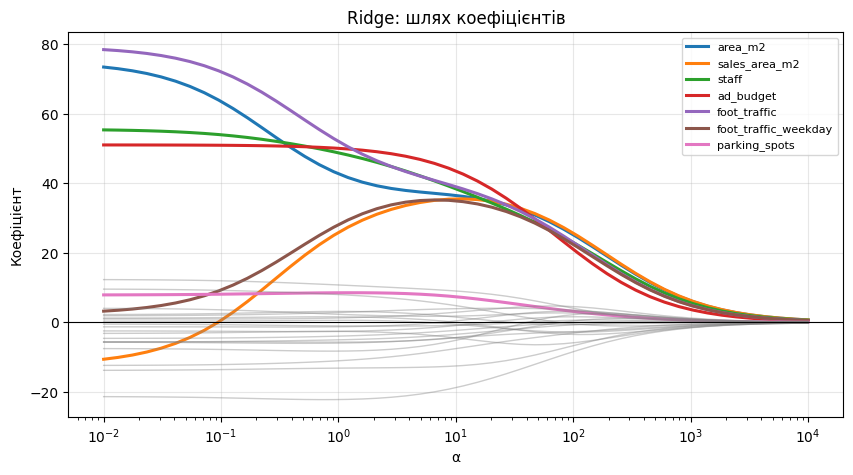

In [111]:
# alpha_grid = np.logspace(-2, 4, 50)
# path = np.array([make_pipeline(StandardScaler(), ВАШ_КОД(alpha=a)).fit(X_train, y_train)[-1].coef_ for a in alpha_grid])

# for j, col in enumerate(X.columns):
#     if col in USEFUL:
#         plt.plot(alpha_grid, path[:, j], linewidth=2.2, label=col)
#     else:
#         plt.plot(alpha_grid, path[:, j], color='gray', alpha=0.4, linewidth=1)
# plt.xscale('ВАШ_КОД')
# plt.axhline(0, color='black', linewidth=0.8)
# plt.title('Ridge: шлях коефіцієнтів')
# plt.xlabel('α')
# plt.ylabel('Коефіцієнт')
# plt.legend(fontsize=8)
# plt.show()


# Створюємо 50 значень alpha від 0.01 до 10000
# Значення розташовані за логарифмічною шкалою
alpha_grid = np.logspace(-2, 4, 50)

# Для кожного alpha навчаємо окрему Ridge-модель
# StandardScaler() масштабує ознаки
# Ridge(alpha=a) задає силу регуляризації
# fit() навчає модель
# [-1].coef_ отримує коефіцієнти Ridge
# np.array() збирає коефіцієнти всіх моделей у масив
path = np.array([
    make_pipeline(
        StandardScaler(),
        Ridge(alpha=a)
    ).fit(X_train, y_train)[-1].coef_
    for a in alpha_grid
])

# Перебираємо всі назви ознак та їхні індекси
for j, col in enumerate(X.columns):

    # Якщо ознака входить до списку корисних
    if col in USEFUL:

        # Малюємо товсту лінію та додаємо назву ознаки
        plt.plot(alpha_grid, path[:, j],
                 linewidth=2.2, label=col)

    # Якщо ознака не входить до списку корисних
    else:

        # Малюємо тонку напівпрозору сіру лінію
        plt.plot(alpha_grid, path[:, j],
                 color='gray', alpha=0.4, linewidth=1)

# Встановлюємо логарифмічну шкалу для осі X
plt.xscale('log')

# Додаємо горизонтальну лінію на рівні нуля
plt.axhline(0, color='black', linewidth=0.8)

# Додаємо назву графіка
plt.title('Ridge: шлях коефіцієнтів')

# Підписуємо горизонтальну вісь
plt.xlabel('α')

# Підписуємо вертикальну вісь
plt.ylabel('Коефіцієнт')

# Показуємо легенду з назвами корисних ознак
plt.legend(fontsize=8)

# Відображаємо готовий графік
plt.show()


**Висновок до завдання 5.4**

Графік показує, як змінюються коефіцієнти Ridge-регресії зі збільшенням параметра α від 0.01 до 10 000.

При великих значеннях α коефіцієнти всіх ознак наближаються до нуля. Це демонструє дію L2-регуляризації, яка обмежує величини коефіцієнтів моделі.

При цьому окремі коефіцієнти можуть змінюватися нерівномірно, а деякі навіть змінюють знак.

Надмірна регуляризація може спричинити недонавчання (underfitting), що підтверджується результатами попереднього завдання.

**Отже, Ridge допомагає зменшувати величини коефіцієнтів і контролювати складність моделі, але для отримання якісних прогнозів важливо правильно підбирати параметр α.**

---

## Блок 6. LASSO-регресія (⏱ 30 хв)

$$\text{Мінімізуємо: MSE} + \alpha \sum |b_j|$$

LASSO не лише стискає коефіцієнти, а й робить частину з них **рівно нулем** — тобто сам **відбирає ознаки**.

```python
model = make_pipeline(StandardScaler(), Lasso(alpha=5, max_iter=50_000))
```

`max_iter` збільшуємо, щоб алгоритм встиг знайти розв'язок.

**Корисний прийом:** ненульові коефіцієнти — `coef[coef != 0]`; їх кількість — `(coef != 0).sum()`.

### Завдання 6.1. Перша LASSO-модель

Навчіть LASSO з α = 5 (з масштабуванням, `max_iter=50_000`). Збережіть кількість ненульових коефіцієнтів (`n_nonzero`) і MAE на test (`mae_test_lasso`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Як у 5.1, тільки `Lasso(alpha=5, max_iter=50_000)`. Кількість ненульових: `(lasso[-1].coef_ != 0).sum()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
lasso = make_pipeline(StandardScaler(), Lasso(alpha=5, max_iter=50_000)).fit(X_train, y_train)
n_nonzero = (lasso[-1].coef_ != 0).sum()
mae_test_lasso = mean_absolute_error(y_test, lasso.predict(X_test))
```

</details>

In [112]:
# Створюємо LASSO-модель із масштабуванням ознак
# StandardScaler() — масштабує ознаки
# alpha=5 — сила L1-регуляризації
# max_iter=50_000 — максимальна кількість ітерацій алгоритму
lasso = make_pipeline(
    StandardScaler(),
    Lasso(alpha=5, max_iter=50_000)
)

# Навчаємо модель на навчальних даних
# X_train — ознаки магазинів
# y_train — реальна місячна виручка
lasso.fit(X_train, y_train)

# Отримуємо коефіцієнти LASSO через coef_
# != 0 перевіряє, які коефіцієнти не дорівнюють нулю
# sum() рахує кількість таких коефіцієнтів
n_nonzero = (lasso[-1].coef_ != 0).sum()

# Робимо прогноз виручки для тестових магазинів
# Обчислюємо середню абсолютну помилку MAE
mae_test_lasso = mean_absolute_error(
    y_test,
    lasso.predict(X_test)
)

# Виводимо кількість ненульових коефіцієнтів
# X.shape[1] — загальна кількість ознак у таблиці
print(f'Ненульових коефіцієнтів: {n_nonzero} з {X.shape[1]}')

# Порівнюємо помилки трьох регресійних моделей
print(f'MAE test: звичайна = {mae_test_ols:.1f} | Ridge = {mae_test_ridge:.1f} | LASSO = {mae_test_lasso:.1f}')


Ненульових коефіцієнтів: 8 з 27
MAE test: звичайна = 52.9 | Ridge = 46.5 | LASSO = 38.6


In [113]:
check('6.1', n_nonzero, mae_test_lasso)

✅ Завдання 6.1: правильно! Можна рухатися далі.


**Висновок до завдання 6.1**

LASSO-регресія з параметром α = 5 залишила 8 ненульових коефіцієнтів із 27, обнуливши коефіцієнти решти 19 ознак.

Це демонструє особливість L1-регуляризації — здатність автоматично виконувати відбір ознак (Feature Selection).

На тестовій вибірці LASSO показала найменшу середню абсолютну помилку (MAE = 38.6 тис. грн) порівняно зі звичайною лінійною регресією (52.9 тис. грн) та Ridge (46.5 тис. грн).

**Отже, у нашому експерименті LASSO дозволила зменшити кількість ознак із ненульовими коефіцієнтами та покращити точність прогнозування.**

### Завдання 6.2. Які ознаки залишились?

Виведіть ознаки з ненульовими коефіцієнтами LASSO (`kept`). Скільки з них **непотрібні** (не входять до `USEFUL`)? Збережіть у `n_useless_kept`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Зробіть Series з коефіцієнтів, залиште ненульові, візьміть їх назви: `.index`. Непотрібні — ті, яких немає в `USEFUL`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
coef_lasso = pd.Series(lasso[-1].coef_, index=X.columns)
kept = coef_lasso[coef_lasso != 0]
n_useless_kept = sum(name not in USEFUL for name in kept.index)
```

</details>

In [114]:
# Отримуємо коефіцієнти навченої LASSO-моделі
# pd.Series() пов'язує кожен коефіцієнт із назвою ознаки
coef_lasso = pd.Series(lasso[-1].coef_, index=X.columns)

# Залишаємо тільки ознаки, коефіцієнти яких не дорівнюють нулю
kept = coef_lasso[coef_lasso != 0]

# Виводимо залишені ознаки та їхні коефіцієнти
# round(2) округлює коефіцієнти до двох знаків
print(kept.round(2))

# Перевіряємо кожну залишену ознаку
# name not in USEFUL означає, що ознаки немає у списку корисних
# sum() підраховує кількість таких ознак
n_useless_kept = sum(name not in USEFUL for name in kept.index)

# Виводимо кількість непотрібних ознак серед залишених
print(f'\nНепотрібних серед залишених: {n_useless_kept}')


area_m2          39.09
sales_area_m2    28.35
staff            42.89
ad_budget        51.38
foot_traffic     75.80
plants_count      4.00
logo_size_cm     -9.76
noise_04        -10.69
dtype: float64

Непотрібних серед залишених: 3


In [115]:
check('6.2', n_useless_kept)

✅ Завдання 6.2: правильно! Можна рухатися далі.


**✍️ Подивіться на дублікати: `area_m2` / `sales_area_m2` і `foot_traffic` / `foot_traffic_weekday`. Чи залишив LASSO обидві ознаки з кожної пари? Чому так?**
### Висновок до завдання 6.2

LASSO-регресія з параметром α = 5 залишила **8 із 27 ознак** із ненульовими коефіцієнтами.

Із них **5 ознак входять до списку USEFUL**, а **3 є непотрібними** (`plants_count`, `logo_size_cm`, `noise_04`).

Аналіз двох пар сильно пов'язаних ознак показав:

- `area_m2` і `sales_area_m2` — LASSO залишила обидві ознаки.
- `foot_traffic` і `foot_traffic_weekday` — LASSO залишила лише `foot_traffic`, обнуливши коефіцієнт другої ознаки.

Отже, LASSO ефективно скоротила кількість ознак, але не повністю усунула непотрібні та взаємопов'язані ознаки. Це пояснюється особливостями L1-регуляризації та вибраним значенням α.

### Завдання 6.3. Скільки ознак при різних α

Для α зі списку `[0.5, 1, 2, 5, 10, 20]` порахуйте кількість ненульових коефіцієнтів LASSO (`lasso_counts`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Цикл, як у 5.2. Для кожного α — `(m[-1].coef_ != 0).sum()`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
lasso_counts = []
for a in lasso_alphas:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=50_000)).fit(X_train, y_train)
    lasso_counts.append((m[-1].coef_ != 0).sum())
```

</details>

In [116]:
# Список значень alpha, які будемо перевіряти
lasso_alphas = [0.5, 1, 2, 5, 10, 20]

# Створюємо порожній список для кількості ознак
lasso_counts = []

# Перебираємо кожне значення alpha зі списку
for a in lasso_alphas:

    # Створюємо LASSO-модель із поточним alpha
    # StandardScaler() масштабує ознаки
    # Lasso(alpha=a) встановлює силу регуляризації
    # max_iter=50_000 задає максимум ітерацій
    # fit() навчає модель на навчальних даних
    m = make_pipeline(
        StandardScaler(),
        Lasso(alpha=a, max_iter=50_000)
    ).fit(X_train, y_train)

    # m[-1] отримує LASSO з конвеєра
    # coef_ містить коефіцієнти всіх ознак
    # != 0 перевіряє, які коефіцієнти ненульові
    # sum() рахує кількість таких коефіцієнтів
    # append() додає результат до списку
    lasso_counts.append((m[-1].coef_ != 0).sum())

    # Виводимо alpha та кількість залишених ознак
    print(f'α = {a:>4}: ознак у моделі = {lasso_counts[-1]}')



α =  0.5: ознак у моделі = 24
α =    1: ознак у моделі = 22
α =    2: ознак у моделі = 18
α =    5: ознак у моделі = 8
α =   10: ознак у моделі = 7
α =   20: ознак у моделі = 5


In [117]:
check('6.3', lasso_counts)

✅ Завдання 6.3: правильно! Можна рухатися далі.


**Висновок до завдання 6.3**

У результаті дослідження встановлено, що зі збільшенням параметра α кількість ненульових коефіцієнтів LASSO зменшується:

- α = 0.5 — 24 ознаки;
- α = 1 — 22 ознаки;
- α = 2 — 18 ознак;
- α = 5 — 8 ознак;
- α = 10 — 7 ознак;
- α = 20 — 5 ознак.

Найбільше скорочення кількості ознак спостерігається при переході від α = 2 до α = 5: з 18 до 8 ознак.

Отримані результати підтверджують, що посилення L1-регуляризації сприяє обнуленню коефіцієнтів та спрощенню моделі.

Однак занадто велике значення α може призвести до виключення важливих ознак і недонавчання моделі. Тому оптимальне значення α необхідно обирати з урахуванням якості прогнозування, а не лише кількості залишених ознак.

### Завдання 6.4. Ridge чи LASSO?

Для кожної ситуації оберіть **'r'** (Ridge) або **'l'** (LASSO):

1. Маркетологу потрібна модель, яку можна пояснити **коротким списком** із 5–7 факторів.
2. Усі 15 ознак точно корисні, але багато з них сильно **корелюють** між собою.
3. З бази вивантажили 200 колонок, і ви підозрюєте, що **більшість — сміття**.

<details>
<summary><b>💡 Підказка 1</b></summary>

Ridge нічого не обнуляє, але добре справляється з корельованими ознаками. LASSO відбирає ознаки.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Короткий список і «багато сміття» — це відбір ознак. «Усі корисні, але корелюють» — стиснення без обнулення.

</details>

In [118]:
# choice_1 = 'ВАШ_КОД'   # 'r' або 'l'
# choice_2 = 'ВАШ_КОД'
# choice_3 = 'ВАШ_КОД'


# Ситуація 1: потрібен короткий список важливих факторів.
# Обираємо LASSO, оскільки вона виконує відбір ознак.
choice_1 = 'l'

# Ситуація 2: усі ознаки корисні, але сильно корелюють.
# Обираємо Ridge, щоб стабілізувати коефіцієнти
# та зберегти інформацію з усіх ознак.
choice_2 = 'r'

# Ситуація 3: багато потенційно непотрібних ознак.
# Обираємо LASSO, оскільки вона може обнуляти
# коефіцієнти та виключати ознаки з моделі.
choice_3 = 'l'


In [119]:
check('6.4', choice_1, choice_2, choice_3)

✅ Завдання 6.4: правильно! Можна рухатися далі.


**Висновок до завдання 6.4**

Вибір між Ridge та LASSO залежить від особливостей даних і мети бізнес-задачі.

- **Ridge (L2-регуляризація)** доцільно використовувати, коли більшість ознак корисні, але між ними існує сильна кореляція. Цей метод допомагає зменшити та стабілізувати коефіцієнти, зазвичай зберігаючи всі ознаки в моделі.
- **LASSO (L1-регуляризація)** доцільно використовувати, коли в датасеті багато потенційно непотрібних ознак або необхідно отримати простішу модель із невеликою кількістю факторів. Цей метод може обнуляти коефіцієнти, здійснюючи автоматичний відбір ознак.

Обидва методи допомагають боротися з перенавчанням. Остаточний вибір моделі повинен залежати від бізнес-задачі, особливостей даних та якості прогнозування.

---

## Блок 7. Підбір α крос-валідацією (⏱ 20 хв)

У блоці 5 ми обирали α за тестом. **Так робити не можна**: тест — «запечатаний конверт» для фінальної оцінки.

Правильно — **крос-валідація всередині train**: дані ділять на 5 частин, 5 разів навчають на 4 і перевіряють на 5-й. Обирають α з найменшою середньою помилкою.

```python
RidgeCV(alphas=[...])    # перебирає задані α
LassoCV(cv=5)            # сам підбирає набір α
model[-1].alpha_         # обране α
```

### Завдання 7.1. RidgeCV

Навчіть `RidgeCV` з α від 0.01 до 1000 (`np.logspace(-2, 3, 50)`) у pipeline з масштабуванням. Збережіть обране α (`alpha_ridge_cv`) і MAE на test (`mae_ridge_cv`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Замість `Ridge(alpha=...)` — `RidgeCV(alphas=np.logspace(-2, 3, 50))`. Обране α — `ridge_cv[-1].alpha_`.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 50))).fit(X_train, y_train)
alpha_ridge_cv = ridge_cv[-1].alpha_
mae_ridge_cv = mean_absolute_error(y_test, ridge_cv.predict(X_test))
```

</details>

In [120]:
# Створюємо pipeline з масштабуванням ознак
# та RidgeCV для автоматичного підбору alpha
ridge_cv = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-2, 3, 50))
)

# Навчаємо pipeline на навчальних даних
ridge_cv.fit(X_train, y_train)

# Отримуємо значення alpha, яке обрала RidgeCV
alpha_ridge_cv = ridge_cv[-1].alpha_

# Прогнозуємо ціни квартир на тестових даних
# та розраховуємо середню абсолютну помилку MAE
mae_ridge_cv = mean_absolute_error(
    y_test,
    ridge_cv.predict(X_test)
)

# Виводимо обране alpha з двома знаками після крапки
# та MAE з одним знаком після крапки
print(f'Обране α: {alpha_ridge_cv:.2f} | MAE test: {mae_ridge_cv:.1f}')

Обране α: 7.20 | MAE test: 48.2


In [121]:
check('7.1', alpha_ridge_cv, mae_ridge_cv)

✅ Завдання 7.1: правильно! Можна рухатися далі.


**Висновок до завдання 7.1**

За допомогою RidgeCV та крос-валідації було автоматично підібрано значення α = 7.20 серед 50 можливих значень у діапазоні від 0.01 до 1000.

MAE на тестовій вибірці становить 48.2 тис. грн, що краще за результат звичайної лінійної регресії (52.9 тис. грн), але гірше за результат Ridge з α = 10 (46.5 тис. грн).

Автоматичний підбір α за допомогою крос-валідації дозволяє більш обґрунтовано обирати параметр регуляризації без використання тестових даних, проте не гарантує найменшої помилки на конкретній тестовій вибірці.

### Завдання 7.2. LassoCV

Навчіть `LassoCV(cv=5, random_state=0, max_iter=50_000)` у pipeline з масштабуванням. Збережіть обране α (`alpha_lasso_cv`), кількість ненульових коефіцієнтів (`n_nonzero_cv`) і MAE на test (`mae_lasso_cv`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Так само, як RidgeCV. Кількість ненульових — як у 6.1.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
lasso_cv = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=50_000)).fit(X_train, y_train)
alpha_lasso_cv = lasso_cv[-1].alpha_
n_nonzero_cv = (lasso_cv[-1].coef_ != 0).sum()
mae_lasso_cv = mean_absolute_error(y_test, lasso_cv.predict(X_test))
```

</details>

In [122]:
# Створюємо pipeline з масштабуванням ознак
# та автоматичним підбором alpha для LASSO
lasso_cv = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, random_state=0, max_iter=50_000)
)

# Навчаємо модель на навчальних даних
lasso_cv.fit(X_train, y_train)

# Отримуємо автоматично обране значення alpha
alpha_lasso_cv = lasso_cv[-1].alpha_

# Рахуємо кількість ненульових коефіцієнтів
n_nonzero_cv = (lasso_cv[-1].coef_ != 0).sum()

# Розраховуємо MAE на тестових даних
mae_lasso_cv = mean_absolute_error(
    y_test,
    lasso_cv.predict(X_test)
)

# Виводимо обране alpha, кількість ознак та MAE
print(f'Обране α: {alpha_lasso_cv:.2f} | ознак: {n_nonzero_cv} | MAE test: {mae_lasso_cv:.1f}')

Обране α: 5.20 | ознак: 8 | MAE test: 38.4


In [123]:
check('7.2', alpha_lasso_cv, n_nonzero_cv, mae_lasso_cv)

✅ Завдання 7.2: правильно! Можна рухатися далі.


### Завдання 7.3. Чому не за тестом? ⭐ *бонус*

Колега підібрав α, перебравши 100 значень і щоразу дивлячись на MAE на **тесті**. Отриманий MAE він вписав у звіт як «очікувану помилку на нових даних». У чому проблема? → `answer_7_3`

- **а)** проблеми немає, так і роблять
- **б)** α «підігнано» під тест, тож реальна помилка на нових даних, найімовірніше, буде більшою за вказану у звіті
- **в)** 100 значень — забагато, sklearn не дозволяє стільки

<details>
<summary><b>💡 Підказка 1</b></summary>

Якщо тестові дані багато разів використовувати для вибору, вони перестають бути «новими».

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Це як вибрати з 100 спроб найкращий випадковий результат на одному конкретному тесті: на наступному, справді новому тесті він, найімовірніше, буде гіршим.

</details>

In [124]:
# Підбір alpha за тестовими даними порушує
# незалежність тестової вибірки.
# Реальна помилка на нових даних може бути більшою.
answer_7_3 = 'б'

In [125]:
check('7.3', answer_7_3)

✅ Завдання 7.3: правильно! Можна рухатися далі.


**Висновок до завдання 7.3**

Підбір параметра α необхідно здійснювати за допомогою крос-валідації на навчальних даних. Якщо використовувати тестову вибірку для підбору параметрів, вона перестає бути незалежною, а отримана оцінка помилки може бути надто оптимістичною.

---

## Блок 8. Порівняння, інтерпретація і звіт (⏱ 20 хв)

**Як читати коефіцієнти на масштабованих даних:** коефіцієнт = на скільки зміниться прогноз, якщо ознака зросте на **1 стандартне відхилення** (за інших рівних). Тому коефіцієнти можна порівнювати між собою: більший модуль — сильніший вплив.

**Повернути «людські» одиниці:** коефіцієнт ÷ стандартне відхилення ознаки (у pipeline його зберігає scaler: `model[0].scale_`).

### Завдання 8.1. Підсумкове порівняння

Зберіть MAE на test трьох моделей — звичайної регресії, RidgeCV і LassoCV — у список `final_maes` (саме в такому порядку). Запишіть у `best_model` назву найкращої: `'ols'`, `'ridge'` або `'lasso'`.

<details>
<summary><b>💡 Підказка 1</b></summary>

Значення вже пораховані: `mae_test_ols`, `mae_ridge_cv`, `mae_lasso_cv`. Найкраща модель — з **найменшою** MAE.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
final_maes = [mae_test_ols, mae_ridge_cv, mae_lasso_cv]
best_model = ['ols', 'ridge', 'lasso'][np.argmin(final_maes)]
```

</details>

In [126]:
# Збираємо MAE трьох моделей в один список
final_maes = [
    mae_test_ols,
    mae_ridge_cv,
    mae_lasso_cv
]

# Виводимо результати моделей
# з округленням до одного знака після крапки
print(pd.Series(
    final_maes,
    index=['Звичайна', 'RidgeCV', 'LassoCV']
).round(1))

# Знаходимо модель з найменшою MAE
# np.argmin() повертає індекс найменшого значення
best_model = ['ols', 'ridge', 'lasso'][np.argmin(final_maes)]

# Виводимо назву найкращої моделі
print(f'\nНайкраща модель: {best_model}')

Звичайна   52.90
RidgeCV    48.20
LassoCV    38.40
dtype: float64

Найкраща модель: lasso


In [127]:
check('8.1', final_maes, best_model)

✅ Завдання 8.1: правильно! Можна рухатися далі.


### Завдання 8.2. Найважливіша ознака і реклама в «людських» одиницях

Для моделі `lasso_cv`: (1) знайдіть ознаку з **найбільшим за модулем** коефіцієнтом (`top_feature`); (2) переведіть коефіцієнт `ad_budget` у звичайні одиниці: на скільки тис. грн змінюється виручка при +1 тис. грн реклами (`ad_effect`).

<details>
<summary><b>💡 Підказка 1</b></summary>

Найбільша за модулем: `coef.abs().idxmax()`. Стандартні відхилення ознак у pipeline: `lasso_cv[0].scale_` — масив у тому ж порядку, що й колонки X.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

```python
coef_cv = pd.Series(lasso_cv[-1].coef_, index=X.columns)
top_feature = coef_cv.abs().idxmax()
scales = pd.Series(lasso_cv[0].scale_, index=X.columns)
ad_effect = coef_cv['ad_budget'] / scales['ad_budget']
```

</details>

In [128]:
# Отримуємо коефіцієнти навченої LassoCV
# та пов'язуємо їх із назвами ознак
coef_cv = pd.Series(
    lasso_cv[-1].coef_,
    index=X.columns
)

# Виводимо лише ненульові коефіцієнти
print(coef_cv[coef_cv != 0].round(2))

# Знаходимо ознаку з найбільшим
# за абсолютною величиною коефіцієнтом
top_feature = coef_cv.abs().idxmax()

# Отримуємо стандартні відхилення ознак
# зі StandardScaler
scales = pd.Series(
    lasso_cv[0].scale_,
    index=X.columns
)

# Переводимо коефіцієнт рекламного бюджету
# з масштабованих у початкові одиниці
ad_effect = coef_cv['ad_budget'] / scales['ad_budget']

# Виводимо назву найважливішої ознаки
print(f'\nНайважливіша ознака: {top_feature}')

# Виводимо прогнозовану зміну виручки
# при збільшенні рекламного бюджету на 1 тис. грн
print(f'+1 тис. грн реклами → виручка {ad_effect:+.2f} тис. грн')

area_m2          38.44
sales_area_m2    29.07
staff            42.60
ad_budget        51.24
foot_traffic     75.60
plants_count      3.73
logo_size_cm     -9.57
noise_04        -10.44
dtype: float64

Найважливіша ознака: foot_traffic
+1 тис. грн реклами → виручка +3.24 тис. грн


In [129]:
check('8.2', top_feature, ad_effect)

✅ Завдання 8.2: правильно! Можна рухатися далі.


**✍️ Ми генерували дані так, що +1 тис. грн реклами дає +3.5 тис. грн виручки. Чому LASSO показує трохи інше число?**

**Відповідь:**

LASSO використовує регуляризацію, яка зменшує величини коефіцієнтів для боротьби з перенавчанням. Крім того, навчальні дані містять випадковий шум, а модель навчається на обмеженій вибірці. Тому оцінений коефіцієнт рекламного бюджету може відрізнятися від початкового значення 3.5. Це не є помилкою моделі.

### Завдання 8.3. Звіт для керівника мережі

Напишіть звіт з 5–7 речень простою мовою. У ньому має бути:

1. яку задачу розв'язували і чому звичайна регресія не впоралась;
2. яку модель обрали і наскільки вона точна на нових магазинах (MAE);
3. які чинники модель вважає важливими, а які відкинула;
4. одне застереження щодо інтерпретації.

<details>
<summary><b>💡 Підказка 1</b></summary>

Перегляньте результати блоків 3, 6, 7 і 8.

</details>

<details>
<summary><b>💡 Підказка 2 (майже відповідь)</b></summary>

Шаблон: «Ми прогнозували місячну виручку магазину за 27 показниками. Звичайна регресія … . Найкраще впоралась … : на магазинах, яких модель не бачила, вона помиляється в середньому на … тис. грн. Модель вважає важливими … і відкинула … . Варто пам'ятати, що …»

</details>

In [130]:
# Виводимо MAE звичайної лінійної регресії
print(f'MAE звичайної регресії: {mae_test_ols:.1f}')

# Виводимо MAE RidgeCV
print(f'MAE RidgeCV: {mae_ridge_cv:.1f}')

# Виводимо MAE LassoCV
print(f'MAE LassoCV: {mae_lasso_cv:.1f}')

# Виводимо назву найкращої моделі
print(f'Найкраща модель: {best_model}')

# Виводимо обране значення alpha для LassoCV
print(f'Обране α: {alpha_lasso_cv:.2f}')

# Виводимо кількість залишених ознак
print(f'Залишено ознак: {n_nonzero_cv} з {X.shape[1]}')

# Виводимо ознаки, які залишила LASSO
print('\nЗалишені ознаки:')
print(coef_cv[coef_cv != 0].round(2))

# Виводимо ознаки, які LASSO відкинула
print('\nВідкинуті ознаки:')
print(coef_cv[coef_cv == 0].index.tolist())

# Виводимо найважливішу ознаку
print(f'\nНайважливіша ознака: {top_feature}')

# Виводимо оцінений вплив рекламного бюджету
print(f'Вплив реклами: {ad_effect:.2f}')

MAE звичайної регресії: 52.9
MAE RidgeCV: 48.2
MAE LassoCV: 38.4
Найкраща модель: lasso
Обране α: 5.20
Залишено ознак: 8 з 27

Залишені ознаки:
area_m2          38.44
sales_area_m2    29.07
staff            42.60
ad_budget        51.24
foot_traffic     75.60
plants_count      3.73
logo_size_cm     -9.57
noise_04        -10.44
dtype: float64

Відкинуті ознаки:
['foot_traffic_weekday', 'parking_spots', 'manager_age', 'wifi_speed_mbps', 'music_volume', 'noise_01', 'noise_02', 'noise_03', 'noise_05', 'noise_06', 'noise_07', 'noise_08', 'noise_09', 'noise_10', 'noise_11', 'noise_12', 'noise_13', 'noise_14', 'noise_15']

Найважливіша ознака: foot_traffic
Вплив реклами: 3.24


**✍️ Звіт для керівника (5–7 речень):**

### Підсумковий звіт для керівника торговельної мережі

Метою дослідження було прогнозування місячної виручки магазинів торговельної мережі на основі 27 показників із використанням навчальних даних про 90 магазинів.

Звичайна лінійна регресія частково підлаштувалася під випадкові закономірності в даних, що призвело до перенавчання та середньої абсолютної помилки прогнозування 52,9 тис. грн.

Найкращий результат серед досліджених моделей показала LassoCV, середня абсолютна помилка якої на тестовій вибірці становить 38,4 тис. грн, що на 27,4% менше порівняно зі звичайною регресією.

Модель залишила 8 із 27 показників, серед яких найбільш важливими за величиною масштабованих коефіцієнтів є відвідуваність магазинів, рекламний бюджет, кількість персоналу, загальна та торгова площі.

Модель відкинула 19 ознак, зокрема вік менеджера, швидкість Wi-Fi, гучність музики та більшість випадкових шумових показників, хоча три шумові ознаки залишилися.

За оцінкою моделі, збільшення рекламного бюджету на 1 тис. грн пов'язане зі збільшенням прогнозованої місячної виручки на 3,24 тис. грн за інших незмінних умов.

Рекомендується розглядати LassoCV як перспективну модель для прогнозування виручки, однак перед практичним застосуванням необхідно перевірити її на незалежних реальних даних, оскільки дослідження проведено на штучно згенерованій вибірці, а статистичні залежності не доводять причинно-наслідкових зв'язків.

---
## 🎉 Готово!

Ви навчилися читати помилки Python, ставити «запобіжники» `assert`, а також бачити перенавчання і виправляти його за допомогою Ridge і LASSO з підбором α крос-валідацією.

**Перед здачею:** *Runtime → Restart and run all* (у Colab) — переконайтеся, що весь блокнот запускається зверху вниз без помилок.